Enter the values of a, b, and p separated by spaces: 2 3 101
Points on the elliptic curve: [(1, 39), (1, 62), (3, 95), (3, 6), (5, 80), (5, 21), (9, 12), (9, 89), (10, 66), (10, 35), (11, 12), (11, 89), (13, 99), (13, 2), (17, 1), (17, 100), (18, 66), (18, 35), (20, 8), (20, 93), (21, 69), (21, 32), (23, 46), (23, 55), (25, 86), (25, 15), (27, 34), (27, 67), (30, 46), (30, 55), (35, 86), (35, 15), (40, 94), (40, 7), (41, 86), (41, 15), (44, 58), (44, 43), (47, 71), (47, 30), (48, 46), (48, 55), (49, 40), (49, 61), (50, 60), (50, 41), (52, 27), (52, 74), (56, 71), (56, 30), (57, 51), (57, 50), (60, 36), (60, 65), (61, 19), (61, 82), (62, 87), (62, 14), (63, 91), (63, 10), (64, 68), (64, 33), (66, 36), (66, 65), (67, 18), (67, 83), (69, 81), (69, 20), (73, 66), (73, 35), (76, 36), (76, 65), (79, 44), (79, 57), (81, 12), (81, 89), (84, 56), (84, 45), (85, 97), (85, 4), (90, 8), (90, 93), (92, 8), (92, 93), (93, 92), (93, 9), (95, 52), (95, 49), (96, 26), (96, 75), (98, 24), (98, 77), (99,

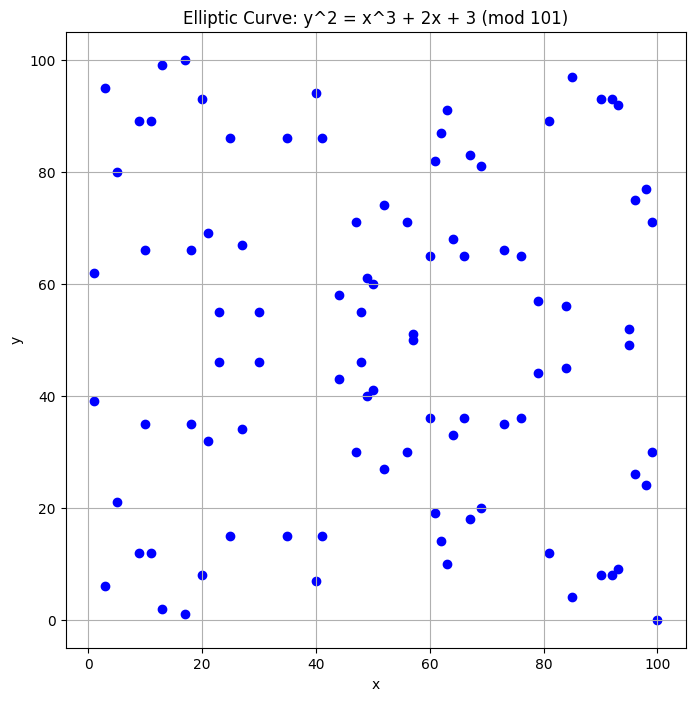

In [1]:
import matplotlib.pyplot as plt

def modular_sqrt(n, p):
    """ Return the square root of n modulo p, if exists, else return None. """
    if pow(n, (p - 1) // 2, p) != 1:
        return None
    elif p % 4 == 3:
        return euler_formula(n, p)
    elif p % 4 == 1:
        return tonelli_shanks(n, p)
    return None

def euler_formula(n, p):
    return pow(n, (p + 1) // 4, p)

def tonelli_shanks(n, p):
    """Use Tonelli–Shanks algorithm for p ≡ 1 (mod 4)."""
    if pow(n, (p - 1) // 2, p) != 1:
        return None  # n is not a quadratic residue modulo p
    q = p - 1
    s = 0
    while q % 2 == 0:
        q //= 2
        s += 1
    z = 2
    while pow(z, (p - 1) // 2, p) != p - 1:
        z += 1
    m = s
    c = pow(z, q, p)
    t = pow(n, q, p)
    r = pow(n, (q + 1) // 2, p)
    while t != 1:
        t2i = t
        for i in range(1, m):
            t2i = pow(t2i, 2, p)
            if t2i == 1:
                break
        b = pow(c, 2 ** (m - i - 1), p)
        m = i
        c = pow(b, 2, p)
        t = (t * c) % p
        r = (r * b) % p
    return r

def plot_elliptic_curve(a,b,p,points):
    x_vals = [point[0] for point in points]
    y_vals = [point[1] for point in points]

    plt.figure(figsize=(8, 8))
    plt.scatter(x_vals, y_vals, color='blue')
    plt.title(f'Elliptic Curve: y^2 = x^3 + {a}x + {b} (mod {p})')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.grid(True)
    plt.show()

def elliptic_curve_points(a,b,p):
    points = []
    for x in range(p):
        y2 = (x**3 + a * x + b) % p
        y = modular_sqrt(y2, p)
        if y is not None:
            points.append((x, y))
            if y != p - y:
                points.append((x, p - y))
        # Check for points where y = 0
        if y2 == 0:
            points.append((x, 0))
    return points


# Example values
a,b,p = map(int,input("Enter the values of a, b, and p separated by spaces: ").split())

points = elliptic_curve_points(a,b,p)
print("Points on the elliptic curve:", points)
print("Number of points including origin o(0,0): ", len(points)+1)
plot_elliptic_curve(a,b,p,points)